# **Digital Image lossless Compression and Extraction Using Huffman coding**

---------------------------------
Choose options
1)To compress an image
2)To decompress an image
3)To exit!


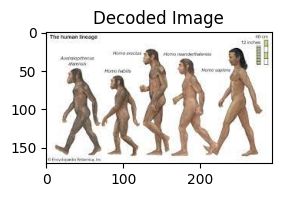

error: OpenCV(4.7.0) D:\a\opencv-python\opencv-python\opencv\modules\imgcodecs\src\loadsave.cpp:692: error: (-2:Unspecified error) could not find a writer for the specified extension in function 'cv::imwrite_'


In [2]:
#Importing necessary libraries
import cv2
import numpy as np
from matplotlib import pyplot as plt
import gzip
import bitarray
import struct
import pickle


#Node Structure/class

class Node:
   def __init__(self, key=None,freq=None):
      self.freq = freq
      self.key = key
      self.left = None
      self.right = None


#2.Making dictionary for the pixel-values and frequency of that pixel-value
def pixelDict(img,pixels_dict):
    rows,cols,dims = img.shape
    for i in range(rows):
        for j in range(cols):
            for k in range(dims):
                if img[i,j,k] in pixels_dict:
                    pixels_dict[img[i,j,k]]+=1
                else:
                    pixels_dict[img[i,j,k]]=1
    return pixels_dict


#3.Add all values into min-heap
def make_minHeap(pixels_dict):
  min_heap=[0]
  for key in pixels_dict.keys():
      newNode = Node(key,pixels_dict[key])
      min_heap.append(newNode)
  return min_heap


#min-heap

def PARENT(i):
 return int(i/2)

def LEFT(i):
 return 2*i

def RIGHT(i):
 return 2*i + 1

#inser to min-heap
def insertToMinHeap(A,x):
  A.append(x)
  i = len(A)-1
  while(i>1 and A[PARENT(i)].freq > A[i].freq):
    temp = A[PARENT(i)]
    A[PARENT(i)]= A[i]
    A[i]=temp
    i=PARENT(i)


#min-heapify
def minHeapify(A,i):
    L=LEFT(i)
    r=RIGHT(i)

    if L < len(A) and A[L].freq < A[i].freq:
      smallest = L
    else:
      smallest = i
    
    if r < len(A) and A[r].freq < A[smallest].freq:
      smallest = r
    
    if(smallest != i):
      temp = A[smallest]
      A[smallest]=A[i]
      A[i]=temp
      minHeapify(A,smallest)

#min-heap minimum
def minHeapMinimum(A):
  if (len(A)>0):
    return A[1]
  else:
    return -1

#min-heap extract min
def minHeapExtractMin(A):
  min = minHeapMinimum(A)
  A[1]=A[-1]
  A.pop()
  minHeapify(A,1)
  return min

#build min-heap
def buildMinHeap(A,n):
  n=int(n/2)
  for i in range(0,n):
    minHeapify(A,n-i)

# Huffman Coding for Image Compression

def huffmanTree(min_heap):  
  while(len(min_heap)>2):
      x = minHeapExtractMin(min_heap)
      y = minHeapExtractMin(min_heap)
      z = Node(None,x.freq+y.freq)
      z.left = x
      z.right = y
      insertToMinHeap(min_heap,z)

def assignCodes(node, code, huffmanCodes):
      if node.key is not None:
          # Leaf node
          huffmanCodes[node.key] = code
      else:
          # Internal node
          assignCodes(node.left, code + '0',huffmanCodes)
          assignCodes(node.right, code + '1',huffmanCodes)


def huffmanCoding(img,min_heap):
    huffmanCodes = dict()
    assignCodes(min_heap[1], '',huffmanCodes)
    rows,cols,dims=img.shape
    huffmanCodes["rows"]=rows
    huffmanCodes["cols"]=cols
    huffmanCodes["dims"]=dims
    return huffmanCodes

# Step 4: Compress the image using the Huffman codes
def image_compression_str(img,huffmanCodes):   
  rows,cols,dims = img.shape
  compressed_image_str = ''
  for i in range(rows):
      for j in range(cols):
          for k in range(dims):
              compressed_image_str += huffmanCodes[img[i,j,k]]
  return compressed_image_str

def save_compressed_file(encoded_image, output_file,huffmanCodes):    
    extra_padding = 8 - len(encoded_image) % 8
    for i in range(extra_padding):
        encoded_image += "0"

    padded_info = "{0:08b}".format(extra_padding)
    encoded_image = padded_info + encoded_image

    bits = bitarray.bitarray(encoded_image)

    with gzip.open(output_file, 'wb') as f:

        num_pairs = len(huffmanCodes)
        f.write(struct.pack('I', num_pairs))

        for key, value in huffmanCodes.items():
            key_bytes = pickle.dumps(key)
            value_bytes = pickle.dumps(value)
            
            key_len = len(key_bytes)
            value_len = len(value_bytes)
            
            f.write(struct.pack('2I', key_len, value_len))
            f.write(key_bytes)
            f.write(value_bytes)
    
        f.write(struct.pack('I', len(bits)))
        f.write(bits)
  
def binToInt(binary):
      sum=0
      i=1
      for j in binary[::-1]:
          val = int(j)*i
          if(val>0):
              sum +=int(j)*i
          i=i*2
      return sum

def convertToImg(compressed_image,codes,filename):
    rows=codes["rows"]
    cols=codes["cols"]
    dims=codes["dims"]
    decoded_image = np.zeros((rows,cols,dims), np.uint8)
    code = ''
    k = 0
    for i in range(rows):
        for j in range(cols):
            for p in range(dims):
                while(1):
                    code += compressed_image[k]
                    if code in codes.values():
                        index = list(codes.values()).index(code)
                        decoded_image[i,j,p] = list(codes.keys())[index]
                        code = ''
                        k +=1
                        break
                    k += 1
    plt.subplot(1, 2, 2)
    plt.title('Decoded Image')
    plt.imshow(cv2.cvtColor(decoded_image, cv2.COLOR_BGR2RGB))
    plt.show()
    cv2.imwrite(filename, decoded_image)

def compress_img(imagepath,output_file):
    img = cv2.imread(imagepath)
    pixels_dict=dict()
    pixels_dict = pixelDict(img,pixels_dict)
    min_heap = make_minHeap(pixels_dict)
    buildMinHeap(min_heap,len(min_heap))
    huffmanTree(min_heap)
    huffmanCodes = huffmanCoding(img,min_heap)
    compressed_img_str = image_compression_str(img,huffmanCodes)
    save_compressed_file(compressed_img_str,output_file,huffmanCodes)

def decompress_img(input_file,decompress_file):
    with gzip.open(input_file, 'rb') as f:
        num_pairs = struct.unpack('I', f.read(4))[0]
    
        codes = {}
        for i in range(num_pairs):
            key_len, value_len = struct.unpack('2I', f.read(8))
            
            key_bytes = f.read(key_len)
            value_bytes = f.read(value_len)
            
            key = pickle.loads(key_bytes)
            value = pickle.loads(value_bytes)

            codes[key] = value
    
        bitstream_len = struct.unpack('I', f.read(4))[0]
        bitstream = f.read(bitstream_len)

        bits = bitarray.bitarray()
        bits.frombytes(bitstream)

        bit_string = bits.to01()

        padvalue=binToInt(bit_string[0:8])
        actual_encoded_img = bit_string[8:-1*padvalue]

        convertToImg(actual_encoded_img,codes,decompress_file)

        
        

while(1):
  print("---------------------------------")
  print("Choose options\n1)To compress an image\n2)To decompress an image\n3)To exit!")
  option=int(input())
  if(option == 1):
    imgname=input("Enter the Image filename:")
    filename=input("Enter the filename to store the compressed image:")
    compress_img(imgname,filename)
  elif(option == 2):
    imgname=input("Enter the filename of compressed image:")
    filename=input("Enter the filename to store the decompressed image:")
    decompress_img(imgname,filename)
  else:
    break